# M3 part 2: Tsao's stepwise table, Kanter's timescales and part 2, the ramp test

Loads and plots only. Numbers come from:
- `run_unit_timescales.py`: one job per recday, >= 5 trials, `kin='strict'`; `--merge`; `--gate`;
- `run_population_drift.py --part2`: one job per recday; `--part2 --merge`; `--gate-part2`.

Plan and rationale: `docs/handoff/EVENT_KERNELS_WRITEUP.md`, Part 2. Write-ups: `code/EVENT_KERNELS.md`
(Tsao, Kanter single-unit, the ramp test) and `code/POPULATION_DRIFT.md` (Kanter part 2), entries
2026-10-14.

- **Tsao's table** is in sample: a selected term is not evidence of a locked clock; Stage 1 is the test.
- **Kanter's measures** run on raw counts, as he did, and on held-out residuals of the Stage 2 full model,
  because the ABCD task repeats every ~9 s and ~44 s and behaviour changes within a session.
- **The ramp test** asks whether M2's held-out first-minute decoding is the slow entry ramps' early slope
  or a fast component locked to bin 0 (e.g. the white noise at task start, a median 4.6 s after bin 0).

In [1]:
RUN_MODE = 'load'   # never computes; rerun the sbatch jobs and merges instead
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import event_kernels_plots as P
%matplotlib inline
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
fig1 = lambda name: os.path.join(P.M3P2_FIG_DIR, name)
fig2 = lambda name: os.path.join(P.M3P2_DRIFT_FIG_DIR, name)
TS = {'LEC': P.load_latest(os.path.join(P.TS_DIR, 'timescales_lec_kin-strict_mt5_np100')),
      'PFC': P.load_latest(os.path.join(P.TS_DIR, 'timescales_pfc_kin-strict_mt5_np100'))}
P2 = {'LEC': P.load_latest(os.path.join(P.PART2_DIR, 'part2_lec_mt5')),
      'PFC': P.load_latest(os.path.join(P.PART2_DIR, 'part2_pfc_mt5'))}
S2 = {'LEC': P.load_latest(os.path.join(P.REPO, 'data', 'event_kernels', 'stage2', 'stage2_lec_kin-strict_mt5_np100')),
      'PFC': P.load_latest(os.path.join(P.REPO, 'data', 'event_kernels', 'stage2', 'stage2_pfc_kin-strict_mt5_np100'))}
for ds in TS:
    print(ds, os.path.basename(TS[ds]['_path']), os.path.basename(P2[ds]['_path']))

LEC timescales_lec_kin-strict_mt5_np100.pkl part2_lec_mt5.pkl
PFC timescales_pfc_kin-strict_mt5_np100.pkl part2_pfc_mt5.pkl


## Gates (planted units and populations on the gate recdays' real behaviour)

In [2]:
g = P.table_m3p2_gates()
g[['dataset', 'gate', 'check', 'value', 'passed', 'must']]

,dataset,gate,check,value,passed,must
0,LEC,T1,entry ramps tau 60 s: entry_time selected,0.0,True,False
1,LEC,T1,entry ramps tau 120 s: entry_time selected,0.5,True,False
2,LEC,T1,entry ramps tau 300 s: entry_time selected,1.0,True,True
3,LEC,T2,day trends: day_time selected,1.0,True,True
4,LEC,T3,reward ramps: leg_time or place selected,1.0,True,True
...,...,...,...,...,...,...
69,PFC,P11,shared_axis: leg vs session offset / stability...,19.3 / 0.6 / 0.7,True,True
70,PFC,P15,noise: leg vs session offset / stability leg /...,81.2 / 50.4 / 63.2,True,True
71,PFC,P12,subset_drift: drift growth all / top-25% remov...,0.0144 / -0.0001 / 0.0145; -0.01,True,True
72,PFC,P13,drift: drift growth all / top-25% removed / ra...,0.1838 / 0.1416 / 0.1835; 0.77,True,True


## Equivalences: held-out model = Stage 2 full model; raw ramp-test kNN = M2 drift arm

In [3]:
pd.concat({ds: m['equivalence'] for ds, m in TS.items()})

check  rows   units  max_rel_diff  passed  max_abs_diff                             note
LEC 0  heldout dev == Stage 2 dev_np  3686  2356.0  2.651108e-14    True           NaN                              NaN
    1        raw kNN == M2 drift arm  3444     NaN           NaN    True           0.0                drift_lec_mt5.pkl
PFC 0  heldout dev == Stage 2 dev_np  2060  1126.0  1.161644e-14    True           NaN                              NaN
    1        raw kNN == M2 drift arm     0     NaN           NaN    True           NaN  no M2 drift arm at min_trials 5

In [4]:
pd.concat({ds: m['summary'].assign(skipped=m['summary']['skipped'].fillna('')) for ds, m in TS.items()})

recday                                            skipped  n_units  n_locked_entry    elapsed_s slurm_job_id
LEC 0   ah08_20250613_20250615                                                         151              46  1674.618213      3766909
    1   ah08_20250616_20250617                                                         164              39  1406.480631      3766910
    2   ah08_20250618_20250619                                                         183              58  1936.683172      3766911
    3   ah08_20250620_20250623                                                         108              14   742.974953      3766912
    4   ah08_20250624_20250625                                                         186              57   925.060726      3766913
    5   ah10_20250613_20250615                                                         139              70  1832.067831      3766914
    6   ah10_20250616_20250617                                                         154              68  2026.105811      3766915
    7   ah10_20250618_20250619                                                         162              79  1616.942517      3766916
    8   ah10_20250620_20250623                                                         153              58  1428.226701      3766917
    9   ah10_20250624_20250625                                                         164              52  1209.003858      3766918
    10  ly05_20250613_20250615                                                         117              24   651.809487      3766919
    11  ly05_20250616_20250617                                                         116              35  1076.068501      3766920
    12  ly05_20250618_20250619                                                         109              28   611.126117      3766921
    13  ly05_20250620_20250623                                                          91              26   399.514252      3766922
    14  ly05_20250624_20250625                                                          74              20   373.494123      3766923
    15  ly06_20250613_20250615                                                          68              22   626.633793      3766924
    16  ly06_20250616_20250617                                                          79              23   871.450693      3766925
    17  ly06_20250618_20250619                                                          76              30   852.930030      3766926
    18  ly06_20250620_20250623                                                          67              25   634.354048      3766927
    19  ly06_20250624_20250625                                                          66              23   524.218839      3766928
    20  ly07_20250613_20250615                                                          73              35   819.439942      3766929
    21  ly07_20250616_20250617                                                          88              41   817.040560      3766930
    22  ly07_20250618_20250619                                                          88              45   866.240591      3766931
    23  ly07_20250620_20250623                                                          89              29   879.229205      3766932
    24  ly07_20250624_20250625                                                          86              25   500.166997      3766933
PFC 0   ab03_01092023_02092023                                                          63              33   611.916366      3766934
    1   ab03_05092023_06092023                                                          64              16   623.907201      3766935
    2   ab03_29082023_30082023                                                          70              22   751.856277      3766936
    3   ah03_12082021_13082021                                                          16               3   187.967964      3766937
    4   ah03_18082021_19082021    

## F22. Tsao's in-sample stepwise table

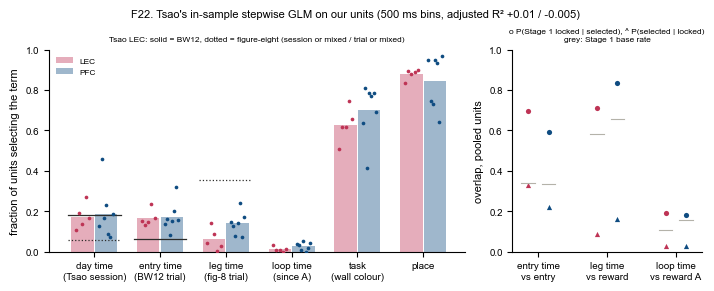

,dataset,term,units,mean_of_mice,lo,hi,pooled,stage1_block,p_stage1_given_tsao,p_tsao_given_stage1,p_stage1_overall
0,LEC,day_time,2851,0.175,0.109,0.270,0.165,NaN,NaN,NaN,NaN
1,LEC,entry_time,2851,0.166,0.132,0.235,0.161,ev_entry,0.696,0.329,0.341
2,LEC,leg_time,2851,0.062,0.006,0.143,0.073,ev_reward,0.713,0.090,0.581
3,LEC,loop_time,2851,0.014,0.000,0.033,0.016,ev_A,0.191,0.029,0.108
4,LEC,task,2851,0.629,0.507,0.744,0.602,NaN,NaN,NaN,NaN
5,LEC,place,2851,0.880,0.837,0.899,0.875,NaN,NaN,NaN,NaN
6,LEC,day or entry time,2851,0.292,0.237,0.393,0.283,NaN,NaN,NaN,NaN
7,PFC,day_time,1229,0.190,0.071,0.458,0.178,NaN,NaN,NaN,NaN
8,PFC,entry_time,1229,0.174,0.086,0.320,0.124,ev_entry,0.595,0.220,0.337
9,PFC,leg_time,1229,0.142,0.076,0.243,0.126,ev_reward,0.832,0.160,0.655


In [5]:
P.plot_tsao_table(TS, out_path=fig1('F22_tsao_table')); plt.show()
P.table_tsao(TS).round(3)

## F23. Tsao's exponential time constants

/ceph/behrens/adam_harris/Taskspace_abstraction_lEC/code/event_kernels_plots.py:1288: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  d = t[t[f'has_{term}'].astype(bool) & t[f'{term}_ok'].fillna(False).astype(bool)][f'{term}_tau_s']
/ceph/behrens/adam_harris/Taskspace_abstraction_lEC/code/event_kernels_plots.py:1288: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  d = t[t[f'has_{term}'].astype(bool) & t[f'{term}_ok'].fillna(False).astype(bool)][f'{term}_tau_s']
/ceph/behrens/adam_harris/Taskspace_abstraction_lEC/code/event_kernels_plots.py:1288: FutureWarnin

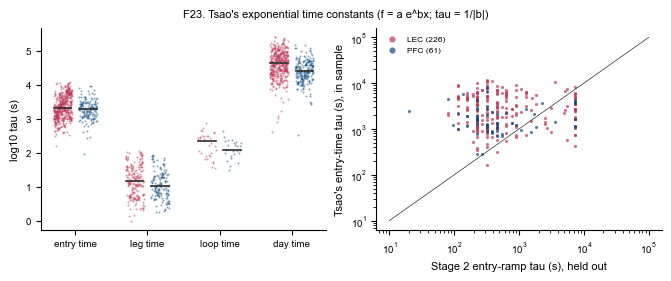

/ceph/behrens/adam_harris/Taskspace_abstraction_lEC/code/event_kernels_plots.py:1270: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  d = t[t[f'has_{term}'].astype(bool) & t[f'{term}_ok'].fillna(False).astype(bool)]
/ceph/behrens/adam_harris/Taskspace_abstraction_lEC/code/event_kernels_plots.py:1270: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  d = t[t[f'has_{term}'].astype(bool) & t[f'{term}_ok'].fillna(False).astype(bool)]
/ceph/behrens/adam_harris/Taskspace_abstraction_lEC/code/event_kernels_plots.py:1270: FutureWarning: Downcasting object dtype arrays

,dataset,term,n,median_tau_s,q25,q75,frac_rising
0,LEC,day_time,425,42483.987,23565.759,73526.419,0.414
1,LEC,entry_time,456,2125.078,1224.781,4202.171,0.612
2,LEC,leg_time,197,15.041,5.912,33.733,0.553
3,LEC,loop_time,33,225.187,86.682,309.398,0.697
4,PFC,day_time,210,24624.031,15306.078,39572.000,0.700
5,PFC,entry_time,153,1950.736,1228.727,2783.014,0.458
6,PFC,leg_time,146,10.570,5.905,20.799,0.589
7,PFC,loop_time,25,122.083,93.923,191.224,0.640


In [6]:
P.plot_tsao_tau(TS, S2, out_path=fig1('F23_tsao_tau')); plt.show()
P.table_tsao_tau(TS, S2).round(3)

## F24-F25. Kanter's single-unit time constants and autocorrelation

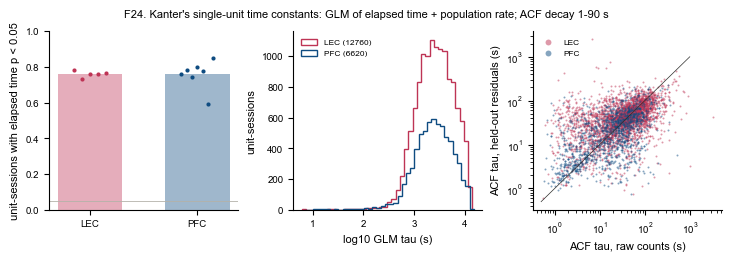

,0,1
dataset,LEC,PFC
unit_sessions,18683,9372
units,2851,1229
sig,1.0,0.964
sig_range,1-1,0.75-1
acf_tau_s,34.511,24.708
acf_tau_s_range,28.5-40.8,4.95-40.9
res_acf_tau_s,41.125,25.536
res_acf_tau_s_range,36.3-49.8,7.84-46.4
acf_tail,0.011,0.01


In [7]:
P.plot_kanter_units(TS, out_path=fig1('F24_kanter_units')); plt.show()
P.table_kanter(TS).round(3).T

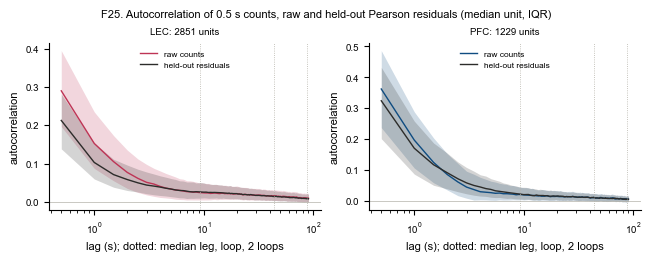

In [8]:
P.plot_acf_curves(TS, out_path=fig1('F25_acf_curves')); plt.show()

## F26. Minute-scale variability: Fano factors and removing the most variable units

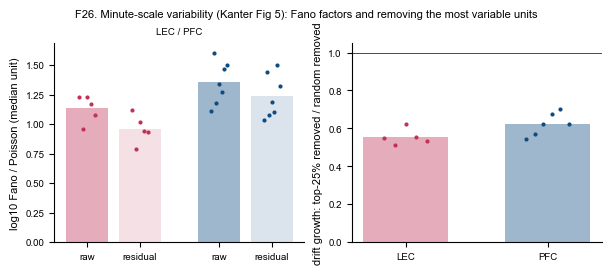

In [9]:
P.plot_fano(TS, P2, out_path=fig2('F26_fano')); plt.show()

## F27. Reward boundaries: preferred transition, ensemble consistency, loop time stamps

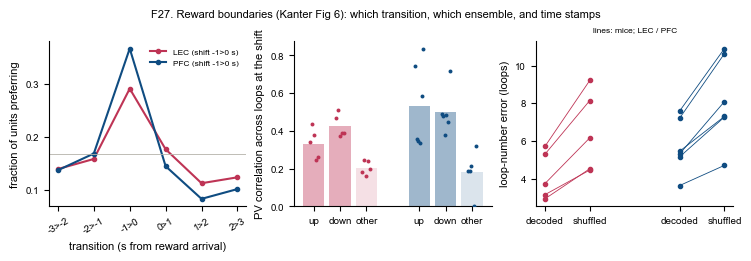

,0,1
dataset,LEC,PFC
shift,-1>0,-1>0
chance,0.167,0.167
frac_pref,0.291,0.367
frac_pref_range,0.242-0.35,0.281-0.422
pv_pos,0.332,0.533
pv_pos_range,0.244-0.435,0.334-0.834
pv_neg,0.425,0.499
pv_neg_range,0.372-0.51,0.377-0.719
pv_other,0.204,0.182


In [10]:
P.plot_boundaries(P2, out_path=fig2('F27_boundaries')); plt.show()
P.table_boundaries(P2).round(3).T

## F28. Coding axes: offsets, stabilities, multiplexing

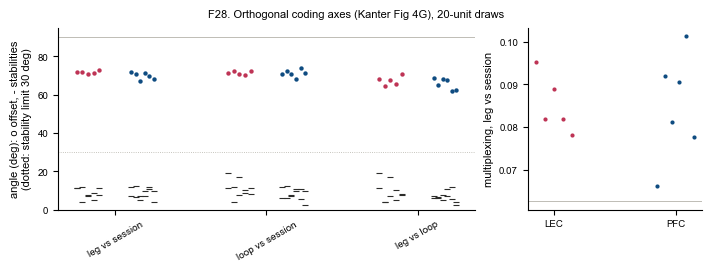

,dataset,set,pair,mice,offset,offset_range,stab_a,stab_a_range,stab_b,stab_b_range,multiplex,multiplex_range,stable,stable_range
0,LEC,all,leg_session,5,78.445,73.1-81.4,9.047,3.21-16.7,14.321,10-21.1,0.083,0.0686-0.0928,0.808,0.691-0.896
1,LEC,all,legA_session,5,76.062,72.8-77.2,20.188,12.6-29.2,14.321,10-21.1,0.087,0.0774-0.0926,0.680,0.567-0.767
2,LEC,all,legB_session,5,78.089,74.6-82.4,24.609,17.9-28,14.321,10-21.1,0.084,0.0755-0.0924,0.653,0.593-0.69
3,LEC,all,legC_session,5,78.023,76-80.5,20.903,11.4-25.9,14.321,10-21.1,0.085,0.0789-0.0879,0.705,0.621-0.767
4,LEC,all,legD_session,5,76.772,73.4-78.9,23.501,8.19-35.7,14.321,10-21.1,0.087,0.0824-0.0937,0.638,0.493-0.85
5,LEC,all,loop_session,5,75.843,73-78.8,14.195,7.32-24,14.321,10-21.1,0.087,0.0822-0.0923,0.779,0.553-0.896
6,LEC,all,leg_loop,5,75.851,70.4-79.8,9.047,3.21-16.7,14.195,7.32-24,0.101,0.0847-0.111,0.798,0.614-0.946
7,LEC,all_n20,leg_session,5,71.697,70.6-72.7,7.018,3.86-11.5,10.228,7.68-11.9,0.085,0.0782-0.0952,0.903,0.858-0.932
8,LEC,all_n20,loop_session,5,71.406,70.2-72.4,11.822,4.1-19.3,10.228,7.68-11.9,0.085,0.0794-0.0913,0.840,0.734-0.911
9,LEC,all_n20,leg_loop,5,67.345,64.4-70.9,7.018,3.86-11.5,11.822,4.1-19.3,0.111,0.0935-0.123,0.859,0.737-0.959


In [11]:
P.plot_axes(P2, out_path=fig2('F28_axes')); plt.show()
P.table_axes(P2).round(3)

## F29-F30. The ramp test

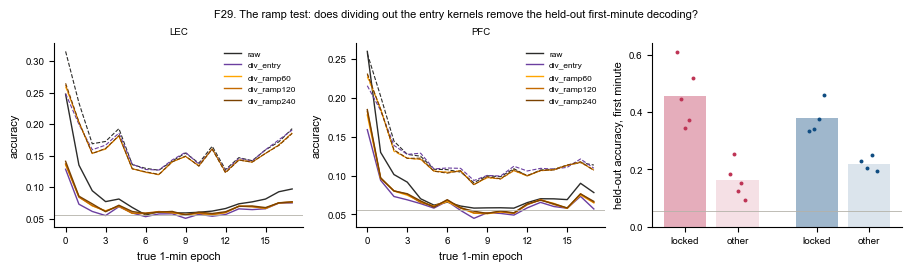

,dataset,set,input,epochs,n_bins,within,across,chance
0,LEC,all_n20,div_entry,minute 1,19680,0.248,0.128,0.056
1,LEC,all_n20,div_entry,minutes 2-17,334560,0.155,0.062,0.056
2,LEC,all_n20,div_ramp120,minute 1,19680,0.262,0.137,0.056
3,LEC,all_n20,div_ramp120,minutes 2-17,334560,0.151,0.066,0.056
4,LEC,all_n20,div_ramp240,minute 1,19680,0.265,0.141,0.056
5,LEC,all_n20,div_ramp240,minutes 2-17,334560,0.151,0.066,0.056
6,LEC,all_n20,div_ramp60,minute 1,19680,0.259,0.136,0.056
7,LEC,all_n20,div_ramp60,minutes 2-17,334560,0.151,0.065,0.056
8,LEC,all_n20,raw,minute 1,19680,0.315,0.248,0.056
9,LEC,all_n20,raw,minutes 2-17,334560,0.159,0.077,0.056


In [12]:
P.plot_ramp_test(TS, out_path=fig1('F29_ramp_test')); plt.show()
P.table_ramp_test(TS).round(3)

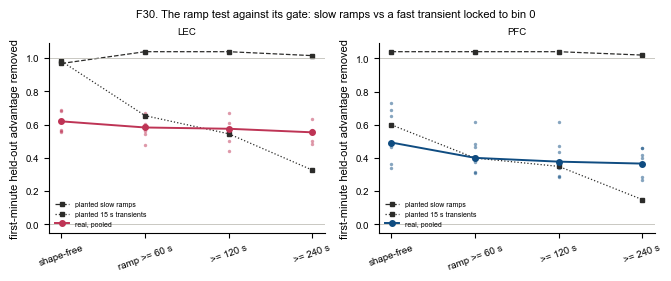

,source,mouse,div_entry,div_ramp60,div_ramp120,div_ramp240
0,LEC real,pooled,0.620,0.583,0.576,0.554
1,LEC real,ah08,0.567,0.545,0.504,0.500
2,LEC real,ah10,0.688,0.607,0.613,0.552
3,LEC real,ly05,0.557,0.477,0.440,0.482
4,LEC real,ly06,0.564,0.565,0.575,0.568
5,LEC real,ly07,0.681,0.670,0.672,0.633
6,LEC planted slow ramps,gate,0.969,1.039,1.039,1.016
7,LEC planted 15 s transients,gate,0.982,0.655,0.545,0.327
8,PFC real,pooled,0.493,0.401,0.378,0.367
9,PFC real,ab03,0.466,0.483,0.471,0.463


In [13]:
P.plot_ramp_envelope(TS, out_path=fig1('F30_ramp_envelope')); plt.show()
P.table_ramp_envelope(TS).round(3)

## LEC regions: ENTl-deep - SUB/ProS, rate-matched, within-recday permutation

In [14]:
P.table_m3p2_regions(TS['LEC']).round(4)

,value,contrast,observed,p_perm,n_units,mice,per_mouse
0,has_entry_time,ENTl-deep - SUB/ProS,0.0487,0.2657,490,4,ah10:+0.114 ly05:+0.293 ly06:-0.203 ly07:-0.009
1,has_leg_time,ENTl-deep - SUB/ProS,0.0401,0.1771,490,4,ah10:+0.154 ly05:-0.027 ly06:-0.018 ly07:+0.051
2,has_day_time,ENTl-deep - SUB/ProS,-0.1259,0.0060,490,4,ah10:-0.092 ly05:-0.140 ly06:-0.040 ly07:-0.231
3,glm_sig,ENTl-deep - SUB/ProS,-0.0108,0.7388,490,4,ah10:+0.051 ly05:-0.142 ly06:-0.016 ly07:+0.064
4,log_res_acf_tau,ENTl-deep - SUB/ProS,-0.1755,0.0002,490,4,ah10:-0.245 ly05:-0.192 ly06:-0.077 ly07:-0.188
5,res_log_fano,ENTl-deep - SUB/ProS,-0.2042,0.0001,490,4,ah10:-0.103 ly05:-0.196 ly06:-0.214 ly07:-0.305
